In [16]:
import glob
import json
import os

import matplotlib.pyplot as plt
import pandas as pd
import torch
from transformers import Qwen3ForCausalLM

import solution as sol

In [17]:
sol.prepare_dataset()  

Creating parquet from Arrow format: 100%|██████████| 61/61 [00:01<00:00, 42.56ba/s]


Saved shard 1/32
Saved shard 2/32
Saved shard 3/32
Saved shard 4/32
Saved shard 5/32
Saved shard 6/32
Saved shard 7/32
Saved shard 8/32
Saved shard 9/32
Saved shard 10/32
Saved shard 11/32
Saved shard 12/32
Saved shard 13/32
Saved shard 14/32
Saved shard 15/32
Saved shard 16/32
Saved shard 17/32
Saved shard 18/32
Saved shard 19/32
Saved shard 20/32
Saved shard 21/32
Saved shard 22/32
Saved shard 23/32
Saved shard 24/32
Saved shard 25/32
Saved shard 26/32
Saved shard 27/32
Saved shard 28/32
Saved shard 29/32
Saved shard 30/32
Saved shard 31/32
Saved shard 32/32


In [18]:
probe_results = []
for bs in [16, 32, 48, 64]:
    try:
        r = sol.train_model(f"probe_bs{bs}", {"per_device_train_batch_size": bs}, probe=True)
        probe_results.append({"bs": bs, **r["speed"]})
    except torch.OutOfMemoryError:
        print(f"OOM at bs={bs}"); sol.cleanup()

import pandas as pd; pd.DataFrame(probe_results)

Generating train split: 1945063 examples [00:10, 191899.25 examples/s]
W1004 12:14:51.562000 88 torch/_dynamo/variables/tensor.py:869] [0/0] Graph break from `Tensor.item()`, consider setting:
W1004 12:14:51.562000 88 torch/_dynamo/variables/tensor.py:869] [0/0]     torch._dynamo.config.capture_scalar_outputs = True
W1004 12:14:51.562000 88 torch/_dynamo/variables/tensor.py:869] [0/0] or:
W1004 12:14:51.562000 88 torch/_dynamo/variables/tensor.py:869] [0/0]     env TORCHDYNAMO_CAPTURE_SCALAR_OUTPUTS=1
W1004 12:14:51.562000 88 torch/_dynamo/variables/tensor.py:869] [0/0] to include these operations in the captured graph.
W1004 12:14:51.562000 88 torch/_dynamo/variables/tensor.py:869] [0/0] 
W1004 12:14:51.562000 88 torch/_dynamo/variables/tensor.py:869] [0/0] Graph break: from user code at:
W1004 12:14:51.562000 88 torch/_dynamo/variables/tensor.py:869] [0/0]   File "/home/jovyan/work/.lib/lib/python3.10/site-packages/accelerate/utils/operations.py", line 814, in forward
W1004 12:14:51.

Training samples: 1940063
Validation samples: 5000
Model pad token id: 2
Total params: 960,881,664
Training config: {
  "max_steps": 40,
  "learning_rate": 0.0006,
  "lr_scheduler_type": "cosine",
  "warmup_ratio": 0.05,
  "per_device_train_batch_size": 16,
  "gradient_accumulation_steps": 1,
  "per_device_eval_batch_size": 64,
  "optim": "adamw_torch_fused",
  "weight_decay": 0.1,
  "adam_beta1": 0.9,
  "adam_beta2": 0.95,
  "max_grad_norm": 1.0,
  "bf16": true,
  "tf32": true,
  "torch_compile": true,
  "gradient_checkpointing": false,
  "dataloader_num_workers": 4,
  "dataloader_pin_memory": true,
  "logging_steps": 5,
  "include_num_input_tokens_seen": true,
  "eval_strategy": "no",
  "eval_steps": 300,
  "save_strategy": "no",
  "save_steps": 300,
  "save_total_limit": 1,
  "save_only_model": true,
  "load_best_model_at_end": false,
  "metric_for_best_model": "eval_loss",
  "greater_is_better": false,
  "report_to": "none",
  "output_dir": "./output_dir/gpt2-1b-russian/probe_bs16"

Step,Training Loss
5,11.985100
10,10.553500
15,9.068900
20,9.101000
25,8.719400
30,8.453900
35,8.326500
40,8.277800


Speed: {'first_step_s(incl. compile)': 40.4, 'median_step_s': 0.1397, 'tokens_per_s(incl. pad)': 58641, 'peak_mem_GB': 16.9}
Model pad token id: 2
Total params: 960,881,664
Training config: {
  "max_steps": 40,
  "learning_rate": 0.0006,
  "lr_scheduler_type": "cosine",
  "warmup_ratio": 0.05,
  "per_device_train_batch_size": 32,
  "gradient_accumulation_steps": 1,
  "per_device_eval_batch_size": 64,
  "optim": "adamw_torch_fused",
  "weight_decay": 0.1,
  "adam_beta1": 0.9,
  "adam_beta2": 0.95,
  "max_grad_norm": 1.0,
  "bf16": true,
  "tf32": true,
  "torch_compile": true,
  "gradient_checkpointing": false,
  "dataloader_num_workers": 4,
  "dataloader_pin_memory": true,
  "logging_steps": 5,
  "include_num_input_tokens_seen": true,
  "eval_strategy": "no",
  "eval_steps": 300,
  "save_strategy": "no",
  "save_steps": 300,
  "save_total_limit": 1,
  "save_only_model": true,
  "load_best_model_at_end": false,
  "metric_for_best_model": "eval_loss",
  "greater_is_better": false,
  "rep

W1004 12:16:17.892000 88 torch/_dynamo/convert_frame.py:906] [11/8] torch._dynamo hit config.cache_size_limit (8)
W1004 12:16:17.892000 88 torch/_dynamo/convert_frame.py:906] [11/8]    function: 'forward' (/home/jovyan/work/.lib/lib/python3.10/site-packages/transformers/models/qwen3/modeling_qwen3.py:201)
W1004 12:16:17.892000 88 torch/_dynamo/convert_frame.py:906] [11/8]    last reason: 11/0: L['self'].layer_idx == 0                                    
W1004 12:16:17.892000 88 torch/_dynamo/convert_frame.py:906] [11/8] To log all recompilation reasons, use TORCH_LOGS="recompiles".
W1004 12:16:17.892000 88 torch/_dynamo/convert_frame.py:906] [11/8] To diagnose recompilation issues, see https://pytorch.org/docs/main/torch.compiler_troubleshooting.html.


...

Speed: {'first_step_s(incl. compile)': 20.3, 'median_step_s': 0.3907, 'tokens_per_s(incl. pad)': 62900, 'peak_mem_GB': 39.5}
Model pad token id: 2
Total params: 960,881,664
Training config: {
  "max_steps": 40,
  "learning_rate": 0.0006,
  "lr_scheduler_type": "cosine",
  "warmup_ratio": 0.05,
  "per_device_train_batch_size": 64,
  "gradient_accumulation_steps": 1,
  "per_device_eval_batch_size": 64,
  "optim": "adamw_torch_fused",
  "weight_decay": 0.1,
  "adam_beta1": 0.9,
  "adam_beta2": 0.95,
  "max_grad_norm": 1.0,
  "bf16": true,
  "tf32": true,
  "torch_compile": true,
  "gradient_checkpointing": false,
  "dataloader_num_workers": 4,
  "dataloader_pin_memory": true,
  "logging_steps": 5,
  "include_num_input_tokens_seen": true,
  "eval_strategy": "no",
  "eval_steps": 300,
  "save_strategy": "no",
  "save_steps": 300,
  "save_total_limit": 1,
  "save_only_model": true,
  "load_best_model_at_end": false,
  "metric_for_best_model": "eval_loss",
  "greater_is_better": false,
  "rep

W1004 12:18:28.758000 88 torch/_dynamo/convert_frame.py:906] [11/8] torch._dynamo hit config.cache_size_limit (8)
W1004 12:18:28.758000 88 torch/_dynamo/convert_frame.py:906] [11/8]    function: 'forward' (/home/jovyan/work/.lib/lib/python3.10/site-packages/transformers/models/qwen3/modeling_qwen3.py:201)
W1004 12:18:28.758000 88 torch/_dynamo/convert_frame.py:906] [11/8]    last reason: 11/0: L['self'].layer_idx == 0                                    
W1004 12:18:28.758000 88 torch/_dynamo/convert_frame.py:906] [11/8] To log all recompilation reasons, use TORCH_LOGS="recompiles".
W1004 12:18:28.758000 88 torch/_dynamo/convert_frame.py:906] [11/8] To diagnose recompilation issues, see https://pytorch.org/docs/main/torch.compiler_troubleshooting.html.


Step,Training Loss
5,11.980900
10,10.082800
15,8.661100
20,8.551100
25,8.336100
30,8.196500
35,8.206100
40,8.169200


Speed: {'first_step_s(incl. compile)': 20.3, 'median_step_s': 0.5204, 'tokens_per_s(incl. pad)': 62972, 'peak_mem_GB': 50.7}


,bs,first_step_s(incl. compile),median_step_s,tokens_per_s(incl. pad),peak_mem_GB
0,16,40.4,0.1397,58641,16.9
1,32,19.9,0.2637,62133,28.1
2,48,20.3,0.3907,62900,39.5
3,64,20.3,0.5204,62972,50.7


In [19]:
t_step    = 0.45   
t_compile = 90     
t_eval, n_eval = 25, 3  
max_steps = int((900 - t_compile - n_eval * t_eval - 30) / t_step)
max_steps

1566

In [20]:
all_results = []

experiments = {
    "baseline_template": {"per_device_train_batch_size": 4, "learning_rate": 5e-5,
                          "lr_scheduler_type": "linear", "warmup_steps": 200, "max_steps": -1},
    "lr3e-4":  {"learning_rate": 3e-4, "max_steps": max_steps},
    "lr6e-4":  {"learning_rate": 6e-4, "max_steps": max_steps},
    "lr1e-3":  {"learning_rate": 1e-3, "max_steps": max_steps},
    "wsd":     {"learning_rate": 6e-4, "max_steps": max_steps,
                "lr_scheduler_type": "warmup_stable_decay",
                "lr_scheduler_kwargs": {"num_decay_steps": max_steps // 5}},
    "adafactor": {"optim": "adafactor", "learning_rate": 1e-3, "max_steps": max_steps},
    "no_compile": {"torch_compile": False, "max_steps": max_steps},
}

for name, ov in experiments.items():
    print(f"\n{'=' * 20} {name} {'=' * 20}")
    r = sol.train_model(name, ov)
    all_results.append({"exp": name, "steps": r["global_step"],
                        "eval_loss": r["eval"]["eval_loss"],
                        "ppl": r["eval"]["perplexity"], **r["speed"]})

pd.DataFrame(all_results).sort_values("eval_loss")


==================== baseline_template ====================
Model pad token id: 2
Total params: 960,881,664
Training config: {
  "max_steps": -1,
  "learning_rate": 5e-05,
  "lr_scheduler_type": "linear",
  "warmup_ratio": 0.05,
  "per_device_train_batch_size": 4,
  "gradient_accumulation_steps": 1,
  "per_device_eval_batch_size": 64,
  "optim": "adamw_torch_fused",
  "weight_decay": 0.1,
  "adam_beta1": 0.9,
  "adam_beta2": 0.95,
  "max_grad_norm": 1.0,
  "bf16": true,
  "tf32": true,
  "torch_compile": true,
  "gradient_checkpointing": false,
  "dataloader_num_workers": 4,
  "dataloader_pin_memory": true,
  "logging_steps": 10,
  "include_num_input_tokens_seen": true,
  "eval_strategy": "steps",
  "eval_steps": 300,
  "save_strategy": "steps",
  "save_steps": 300,
  "save_total_limit": 1,
  "save_only_model": true,
  "load_best_model_at_end": true,
  "metric_for_best_model": "eval_loss",
  "greater_is_better": false,
  "report_to": "none",
  "output_dir": "./output_dir/gpt2-1b-russi

W1004 12:19:42.458000 88 torch/_dynamo/convert_frame.py:906] [11/8] torch._dynamo hit config.cache_size_limit (8)
W1004 12:19:42.458000 88 torch/_dynamo/convert_frame.py:906] [11/8]    function: 'forward' (/home/jovyan/work/.lib/lib/python3.10/site-packages/transformers/models/qwen3/modeling_qwen3.py:201)
W1004 12:19:42.458000 88 torch/_dynamo/convert_frame.py:906] [11/8]    last reason: 11/0: L['self'].layer_idx == 0                                    
W1004 12:19:42.458000 88 torch/_dynamo/convert_frame.py:906] [11/8] To log all recompilation reasons, use TORCH_LOGS="recompiles".
W1004 12:19:42.458000 88 torch/_dynamo/convert_frame.py:906] [11/8] To diagnose recompilation issues, see https://pytorch.org/docs/main/torch.compiler_troubleshooting.html.


Step,Training Loss,Validation Loss,Input Tokens Seen
300,7.924800,7.941639,614400
600,7.301900,7.616100,1228800
900,7.020200,7.426666,1843200
1200,6.880400,7.285784,2457600
1500,6.781600,7.141306,3072000
1800,6.728200,7.048061,3686400
2100,6.352000,6.963456,4300800
2400,6.303700,6.891872,4915200
2700,6.233300,6.827522,5529600
3000,6.424400,6.791677,6144000


Training stopped after 905.68 seconds
Speed: {'first_step_s(incl. compile)': 16.9, 'median_step_s': 0.055, 'tokens_per_s(incl. pad)': 37214, 'peak_mem_GB': 22.4}
Running final evaluation...


Final evaluation results: {'eval_loss': 6.450047969818115, 'eval_runtime': 25.1678, 'eval_samples_per_second': 198.667, 'eval_steps_per_second': 3.139, 'epoch': 0.011754251406139178, 'num_input_tokens_seen': 11675648, 'perplexity': 632.732644154129}

[greedy] 'Москва — столица'
→ Москва — столица.

Известные носители:

 «Пан» () — американский фильм, за фильм «Кин-Хай».
 «Сюси» — американский фильм «Вор-Л» () — американский фильм «Топ»
 «Фильм» — американский фильм «Гам»
 «Кин» () — «Дик»

[sampling] 'Москва — столица'
→ Москва — столицана.

Умерной 
Родился на летних, в том числе 4-е место.

Плей-х годов

В начале 1939 года был образован в Санкт-Петербурге и политической работе за большой института.

Награды и звания 

Ит (1976)
 Почётный гражданин по футболу (с 17 января 2007 года), в Великой

[greedy] 'В 1812 году'
→ В 1812 году в составе.

Входит в состав сборной России по футболу (с 1-е место) и в Москве, где в составе сборной России по хоккею с результатом 2021 года.

Ссылки 
 Пр

...

W1004 13:34:40.147000 88 torch/_dynamo/convert_frame.py:906] [11/8] torch._dynamo hit config.cache_size_limit (8)
W1004 13:34:40.147000 88 torch/_dynamo/convert_frame.py:906] [11/8]    function: 'forward' (/home/jovyan/work/.lib/lib/python3.10/site-packages/transformers/models/qwen3/modeling_qwen3.py:201)
W1004 13:34:40.147000 88 torch/_dynamo/convert_frame.py:906] [11/8]    last reason: 11/0: L['self'].layer_idx == 0                                    
W1004 13:34:40.147000 88 torch/_dynamo/convert_frame.py:906] [11/8] To log all recompilation reasons, use TORCH_LOGS="recompiles".
W1004 13:34:40.147000 88 torch/_dynamo/convert_frame.py:906] [11/8] To diagnose recompilation issues, see https://pytorch.org/docs/main/torch.compiler_troubleshooting.html.


Step,Training Loss,Validation Loss,Input Tokens Seen
300,5.224700,5.839530,4915200
600,4.673100,5.184806,9830400
900,4.154800,4.804118,14745600
1200,3.930500,4.583098,19660800
1500,3.941800,4.543777,24576000


Speed: {'first_step_s(incl. compile)': 7.9, 'median_step_s': 0.266, 'tokens_per_s(incl. pad)': 61584, 'peak_mem_GB': 33.9}
Running final evaluation...


Final evaluation results: {'eval_loss': 4.543776988983154, 'eval_runtime': 25.3998, 'eval_samples_per_second': 196.852, 'eval_steps_per_second': 3.11, 'epoch': 0.025830075708842593, 'num_input_tokens_seen': 25657344, 'perplexity': 94.04533836138873}

[greedy] 'Москва — столица'
→ Москва — столица города.

История 
В начале 1990-х годов, в связи с этим на территории страны, были установлены новые здания и сооружения:

«Станция» (в настоящее время) — «Спасная» (),

«Сельская» (с 2011 года) — «Садовая» ()

«Станция» (с 2009 года

[sampling] 'Москва — столица'
→ Москва — столица города.

Улицы 
 ул. Мира
 ул. Центральная, д. Советская
 ул. Молодёжная, ул. Центральная, 6.

Примечания

Литература 
 
 Гарадывський М.: энциклопедия, 1962, стр. 2 (1973)
 http://www.lr-tekovnumvolka.

[greedy] 'В 1812 году'
→ В 1812 году в составе Российской империи, в 1856 году был создан уездный район.

С 1929 года — в составе уезда Улан-Каймской губернии. В 1922 году он был переименован в Округ Ишимбайского р

,exp,steps,eval_loss,ppl,first_step_s(incl. compile),median_step_s,tokens_per_s(incl. pad),peak_mem_GB
4,wsd,1566,4.373808,79.345234,7.7,0.2658,61637,33.9
3,lr1e-3,1566,4.499320,89.955900,7.9,0.2655,61716,33.9
6,no_compile,1566,4.543777,94.045338,7.9,0.2660,61584,33.9
2,lr6e-4,1566,4.545295,94.188186,7.8,0.2658,61637,33.9
1,lr3e-4,1566,4.695152,109.415469,7.8,0.2657,61669,33.9
5,adafactor,1566,4.804839,122.099848,7.8,0.3099,52860,30.4
0,baseline_template,5701,6.450048,632.732644,16.9,0.0550,37214,22.4


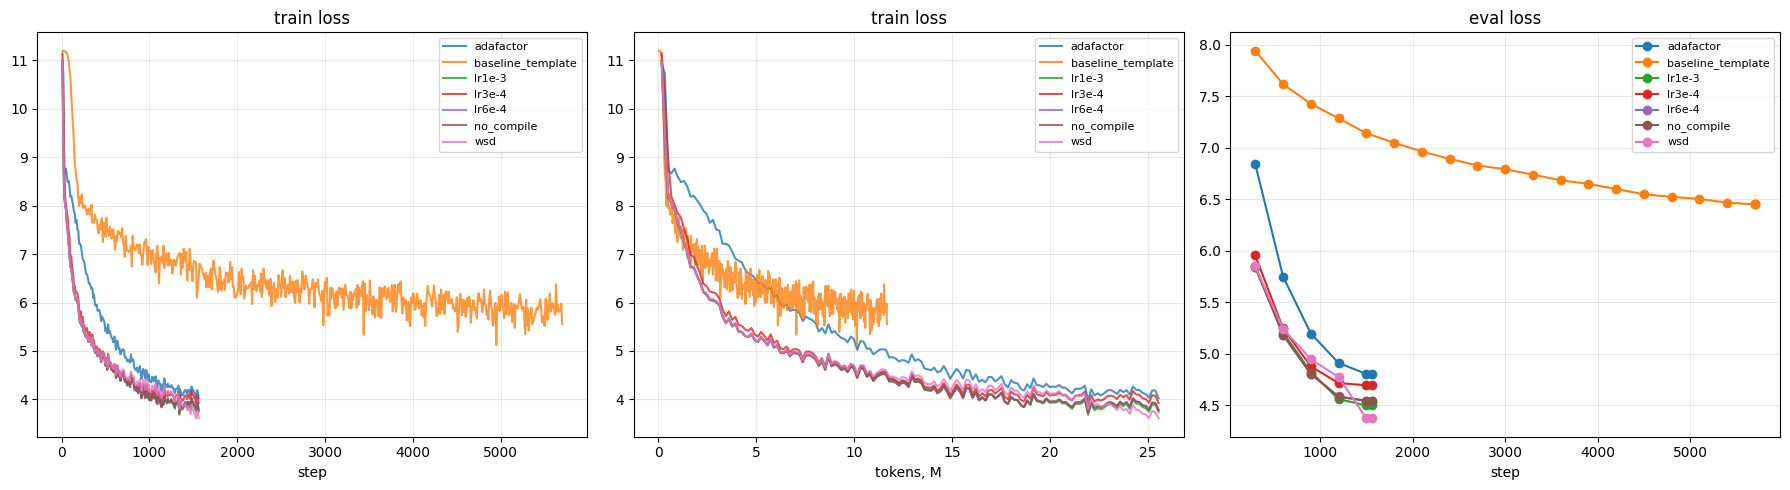

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for run in sorted(glob.glob(f"{sol.RUNS_DIR}/*")):
    path = os.path.join(run, "trainer_state.json")
    if not os.path.exists(path):
        continue
    name = os.path.basename(run)
    hist = json.load(open(path))["log_history"]
    tr = [h for h in hist if "loss" in h]
    ev = [h for h in hist if "eval_loss" in h]
    axes[0].plot([h["step"] for h in tr], [h["loss"] for h in tr], label=name, alpha=.8)
    if tr and "num_input_tokens_seen" in tr[0]:
        axes[1].plot([h["num_input_tokens_seen"] / 1e6 for h in tr], [h["loss"] for h in tr], label=name, alpha=.8)
    axes[2].plot([h["step"] for h in ev], [h["eval_loss"] for h in ev], "o-", label=name)

for ax, (t, x) in zip(axes, [("train loss", "step"), ("train loss", "tokens, M"), ("eval loss", "step")]):
    ax.set_title(t); ax.set_xlabel(x); ax.grid(alpha=.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig("loss_curves.png", dpi=150); plt.show()

In [22]:
tok = sol.prepare_tokenizer()
m = Qwen3ForCausalLM.from_pretrained(f"{sol.RUNS_DIR}/lr6e-4/final",
        torch_dtype=torch.bfloat16, attn_implementation="flash_attention_2").cuda()
sol.generate_samples(m, tok, prompts=["Санкт-Петербург основан", "Физика — это наука"])
del m; sol.cleanup()

You are attempting to use Flash Attention 2.0 with a model not initialized on GPU. Make sure to move the model to GPU after initializing it on CPU with `model.to('cuda')`.



[greedy] 'Санкт-Петербург основан'
→ Санкт-Петербург основан в 1856 году.

В 1872 году, по инициативе архитектора А. А. Круковского, он был назначен на должность до 1857 года и стал членом Государственного совета Российской империи. В 1873—1876 годах был избран председателем Совета Министров СССР от партии «О присвоении звания генерал-майора».

Скончался 1 января 1822 года в Санкт-

[sampling] 'Санкт-Петербург основан'
→ Санкт-Петербург основан в Москве, где он писал: «Лебные материалы, о которых я был не очень много раз, как и что ты были даже быть почти все её художественное».

К концу 1920 года он принял участие на пост-бронный успех. В 1910—1917 годах его сын и жена, а с 1836 года — дочь С. Г. Дольца, с 1859

[greedy] 'Физика — это наука'
→ Физика — это наука, или для обозначения различных видов.

Описание 
Мелкие муравьи (длина тела) с чёрным стеблем. Усики 12-члениковые.

Распространение и экология 
Вид распространён в Южной Америке, на территории России:

Примечания 

Списки:Та